# RAVE-VL v4 · Portion 2 — GPU: profile → B0 uniform-resolution frontier → cross-fitted gates → pre-registration

**Inputs come from Google Drive** (`MyDrive/Koushik 2/rave_work/`, written by Portion 1) and are restored to the fast
local disk automatically, so this works on a brand-new runtime. Every output is mirrored back to Drive after every
phase, and the notebook itself (with outputs) is saved to `Koushik 2/notebooks/` at the end.

**A100 time** = the executed cell time of Portions 2–4, summed across runtimes (the ledger lives on Drive); weight
downloads and the Drive restore are excluded. Every cell prints wall time, CPU time (kernel + DataLoader workers),
GPU busy time (exact CUDA-event time per phase, NVML utilisation per cell), GPU energy and peak host RAM.

**Memory (fits an A100 40 GB and ~40 GB of RAM):** images go to the GPU as bf16 (what the model uses anyway);
8 loader workers × 2 queued batches; every batch is capped in visual tokens so the loader stays within 40% of the
free RAM (max 24 GB); the batch size is the smallest that reaches ≥ 95% of peak throughput with GPU memory ≤ 80%;
a GPU out-of-memory splits the batch instead of crashing, and RAM above 90% restarts the loader with smaller batches.
The progress bars show live RAM and GPU memory.

| Phase | Device | What |
|---|---|---|
| P2.A | GPU | Load BF16 model (FlashAttention-2 if it loads, else SDPA); verify *exact* token counts vs. Portion 1; letter readout = greedy answer; autotune batches; throughput, batch-1 latency, projected minutes for every pass |
| P2.B | GPU | **B0 frontier**: global image only at 256 (main), 1024 (v1), 128, 512, native. One prefill per question; logits read at the answer slot only |
| P2.C | CPU | Gates, all out-of-fold: entropy (A1), **LookWise-style** confidence, **LazyMCoT-style** GBDT router, answer-only LR, **RAVE risk** |
| P2.D | CPU | Risk-controlled acceptance (Learn-then-Test, nested cross-fitting) |
| P2.E | CPU | **Pre-registration** of escalation sets, merge rules, VoI spec and hypotheses (hashed before any crop result) |
| P2.F | CPU | **Figures**: uniform frontier, gate ROC + risk–coverage, reliability, accuracy by image type, risk control |

In [1]:
%pip install -q "transformers>=4.57.0" accelerate "datasets>=3.0" nvidia-ml-py psutil pandas pyarrow scikit-learn scipy tqdm packaging matplotlib
# optional, faster attention on A100 (the notebook falls back to SDPA automatically if it does not load):
# %pip install -q flash-attn --no-build-isolation

In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub=""):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

import torch
NOTEBOOK = "P2"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"     # CPU only for smoke tests with a small model
ON_GPU = DEVICE.startswith("cuda")
LOADER_WORKERS = min(8, max(1, N_CPU - 2))    # 8 keep an A100 busy; more only costs RAM
ESC_RATES = [0.1, 0.2, 0.3, 0.4, 0.5]
MAIN_RATE = 0.3                         # pre-registered operating point
RISK_BASES = [MAIN_BASE, PROTOCOL_BASE]
B0_ORDER = [MAIN_BASE, PROTOCOL_BASE] + [b for b in BASES if b not in (MAIN_BASE, PROTOCOL_BASE)]
LTT_RHO, LTT_DELTA = [0.5, 0.65, 0.8], 0.10   # target: accepted-answer error <= rho x (training-split B0 error)
LOOKWISE_TAU = 0.96                     # LookWise's fixed confidence threshold (reported as an extra point)
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=12 (os.cpu_count()=12) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4"}

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (P2–P4 cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (P2–P4) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: NVIDIA A100-SXM4-40GB | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.00/7 h


In [4]:
# [no-window] restore Portion 1's outputs from Drive (works on a fresh runtime) + fetch the model weights
restore_from_drive()
assert (DIRS["meta"] / "manifest.json").exists(), (
    f"Portion 1 outputs not found in {DRIVE_WORK} — run Portion 1 v4 first (it saves everything to Drive)")
from huggingface_hub import snapshot_download
with Phase(f"P2.download {MODEL_ID} (network, not A100 time)", budget_min=15):
    snapshot_download(MODEL_ID, max_workers=16)
window("start of Portion 2")

restored 21 file(s) from /content/drive/MyDrive/Koushik 2/rave_work + images


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

⏱ P2.download Qwen/Qwen3-VL-8B-Instruct (network, not A100 time) | wall 51.31 s | CPU 102.31 s (1.99 cores, sys 17.8%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.02/7 h
⏱ A100 time start of Portion 2: 0.02 h used, 6.98 h left of 7 h (P2–P4 cells)
⏱ cell 2: # [no-window] restore Portion 1's outputs from Drive (works  | wall 96.00 s | CPU 114.59 s (1.19 cores, sys 21.5%) | GPU busy 0.00 s [nvml_util], util 0.0%, 4.46 kJ | RAM peak 8 GB | A100 time 0.02/7 h


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def tex(s):
    return str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")

def to_booktabs(df, path, caption, label, align=None):
    """Write a LaTeX booktabs table (no jinja2 dependency)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    lines = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}",
             rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.02/7 h


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.02/7 h


## Load Portion 1 artefacts (hash-checked)

In [7]:
import pandas as pd
from tqdm.auto import tqdm

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

with Phase("P2.0 load + verify P1 artefacts", budget_min=2):
    MAN = json.loads((DIRS["meta"] / "manifest.json").read_text())
    for name, h in MAN["sha256"].items():
        assert sha256(DIRS["meta"] / f"{name}.parquet") == h, f"{name}.parquet changed since Portion 1"
    T = {n: pd.read_parquet(DIRS["meta"] / f"{n}.parquet") for n in MAN["sha256"]}
    Q, IMG, SEL, B2, SEQ = T["questions"], T["images"], T["crops"], T["b2"], T["seq_lengths"]
assert MAN["prompt_version"] == PROMPT_VERSION and MAN["bases"] == BASES and MAN["main_base"] == MAIN_BASE
assert MAN["smoke_n"] == SMOKE_N, "Portion 1 and Portion 2 must use the same RAVE_SMOKE_N"
if not SMOKE_N:
    assert len(Q) == 1730, len(Q)
if MAN["model_id"] != MODEL_ID:
    print(f"note: P1 counted tokens with {MAN['model_id']}, P2 runs {MODEL_ID} (same Qwen3-VL tokenizer; P2.A2 re-checks)")
EST = {v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ.groupby("variant")}
VIS = {v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ.groupby("variant")}
QROW = {r.qid: r for r in Q.itertuples()}
print(len(Q), "questions |", len(IMG), "images |", SEQ.variant.nunique(), "prompt variants")

⏱ P2.0 load + verify P1 artefacts | wall 0.18 s | CPU 0.16 s (0.86 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.02/7 h
1730 questions | 2015 images | 17 prompt variants
⏱ cell 5: import pandas as pd | wall 0.52 s | CPU 0.48 s (0.93 cores, sys 8.8%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 4 GB | A100 time 0.02/7 h


In [8]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

MAPS = build_maps(IMG, SEL, B2)

⏱ cell 6: # ── Prompt construction — identical in every portion (P2 ch | wall 0.46 s | CPU 0.46 s (1.0 cores, sys 8.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 4 GB | A100 time 0.02/7 h


## P2.A — Profile & verify

In [9]:
# ── Model, data path and scoring: identical code in Portions 2 and 3 ────────────────────────────
import importlib, gc, transformers
import pandas as pd
from packaging import version
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_num_threads(N_CPU)
COST_FILE = DIRS["logs"] / "variant_costs.json"
PROFILE_FILE = DIRS["logs"] / "gpu_profile.json"
PRED_DIR = DIRS["preds"]          # where dense passes are written (Portion 4 points this elsewhere)
COST_TAG = ""                     # prefix of the per-pass cost records (Portion 4: "hb|" or "4b|")
MAX_OPT = 12                      # MMMU-Pro has up to 12 options (letters A-L); HallusionBench has 2
MAX_TOK = 16384                   # batch token budget; replaced by the autotune / the saved GPU profile
PROFILE_VERSION = 2               # v2: throughput-optimal budget + host-RAM cap (profiles of older runs are redone)

# ── Host-RAM governor ───────────────────────────────────────────────────────────────────────────
# Every LLM visual token is 4 patches x 1536 pixel values. The processor builds them in float32 (24.6 kB per
# visual token, ~3x that while resizing / normalising / patchifying); the batch is then cast to bf16 (12.3 kB) —
# bit-identical to the model's own first step (pixel_values.type(visual.dtype)). Batches in flight =
# workers x prefetch (+2 in the main process). Batches are capped in visual tokens so that this stays inside a
# fixed share of the free RAM, whatever the GPU, the batch budget or the image sizes.
PREFETCH = 2
_VIS_BYTES_READY = 4 * 1536 * 2
_VIS_BYTES_BUILD = 4 * 1536 * 4 * 3
RAM_FRACTION, RAM_CAP_GB = 0.40, 24       # loader may use <= 40% of the free RAM, and never more than 24 GB
RAM_PANIC_PCT = 90                        # above this the loader is restarted with half-size batches
MAX_VIS = 32768

def plan_host_ram():
    vm = psutil.virtual_memory()
    budget = min(RAM_CAP_GB * 1e9, RAM_FRACTION * vm.available)
    per_vis = LOADER_WORKERS * _VIS_BYTES_BUILD + (LOADER_WORKERS * PREFETCH + 2) * _VIS_BYTES_READY
    return max(2048, int(budget / per_vis)), budget, vm

def load_model(src):
    """BF16 Qwen3-VL. FlashAttention-2 if installed AND loadable, otherwise PyTorch SDPA (never crashes on a bad wheel)."""
    dkw = ({"dtype": torch.bfloat16} if version.parse(transformers.__version__) >= version.parse("4.56.0")
           else {"torch_dtype": torch.bfloat16})
    attns = (["flash_attention_2"] if (ON_GPU and importlib.util.find_spec("flash_attn")) else []) + ["sdpa"]
    last = None
    for attn in attns:
        try:
            m = Qwen3VLForConditionalGeneration.from_pretrained(src, attn_implementation=attn, device_map=DEVICE, **dkw)
            return m.eval(), attn
        except Exception as e:
            last = e
            print(f"  {attn} unavailable ({type(e).__name__}: {str(e)[:120]}) -> trying the next option")
    raise last

def configure_processor(proc):
    """Portion 1 resized every image to an exact multiple of 32 px: widen the limits so nothing is resized again."""
    ip = proc.image_processor
    lo, hi = 4 * PX_PER_TOKEN, 16384 * PX_PER_TOKEN
    try:
        from transformers.image_utils import SizeDict
        ip.size = SizeDict(shortest_edge=lo, longest_edge=hi)
    except Exception:
        ip.size = {"shortest_edge": lo, "longest_edge": hi}
    for a, v in (("min_pixels", lo), ("max_pixels", hi)):
        if hasattr(ip, a):
            setattr(ip, a, v)
    proc.tokenizer.padding_side = "left"                 # answer slot = last position of every row
    return proc

def _load(p):
    with Image.open(p) as im:
        return im.convert("RGB")

class QSet(Dataset):
    """One question rendered as prompt variant `variant`; decoding + processor run in DataLoader workers."""
    def __init__(self, variant, qids):
        self.v, self.qids = variant, list(qids)
    def __len__(self):
        return len(self.qids)
    def __getitem__(self, i):
        q = self.qids[i]; row = QROW[q]
        imgs, extra = inputs_for(row, self.v, MAPS)
        msgs, order = build_messages(row, imgs, extra)
        text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return q, row.n_opt, text, [_load(p) for p in order]

def collate(items):
    qids, nopts, texts, imgs = zip(*items)
    flat = [im for L in imgs for im in L]
    enc = processor(text=list(texts), images=flat or None, padding=True, return_tensors="pt")
    assert bool(enc["attention_mask"][:, -1].all()), "padding must be on the left"
    pv = enc.get("pixel_values")
    if pv is not None and pv.dtype == torch.float32:
        enc["pixel_values"] = pv.to(torch.bfloat16)      # half the RAM / PCIe traffic; the model does this cast itself
    return list(qids), list(nopts), enc

def _winit(_):
    torch.set_num_threads(1)

def make_batches(qids, est, max_tokens, max_bs=128, vis=None, max_vis=None):
    """Longest-first packing: (batch size x longest sequence) <= max_tokens -> almost no padding; optionally also
    (sum of visual tokens) <= max_vis, which bounds the host RAM of a batch. A prompt is never split."""
    out, cur, cur_max, cur_vis = [], [], 0, 0
    for q in sorted(qids, key=lambda q: -est[q]):
        L, V = est[q], (vis[q] if vis is not None else 0)
        if cur and (max(cur_max, L) * (len(cur) + 1) > max_tokens or len(cur) >= max_bs
                    or (max_vis and cur_vis + V > max_vis)):
            out.append(cur); cur, cur_max, cur_vis = [], 0, 0
        cur.append(q); cur_max = max(cur_max, L); cur_vis += V
    if cur:
        out.append(cur)
    return out

def batches_for(variant, qids, max_tok=None):
    """The batches every pass uses: GPU token budget AND host-RAM visual-token cap."""
    return make_batches(qids, EST[variant], max_tok or MAX_TOK, vis=VIS.get(variant), max_vis=MAX_VIS)

def loader_for(variant, batches):
    qs = [q for b in batches for q in b]
    idx, s = [], 0
    for b in batches:
        idx.append(list(range(s, s + len(b)))); s += len(b)
    w = LOADER_WORKERS if len(batches) > 1 else 0
    return DataLoader(QSet(variant, qs), batch_sampler=idx, collate_fn=collate, num_workers=w, pin_memory=ON_GPU,
                      prefetch_factor=PREFETCH if w else None, worker_init_fn=_winit if w else None,
                      multiprocessing_context="fork" if w else None)

_USE_LTK = True

@torch.inference_mode()
def forward_last_logits(enc):
    """One prefill, logits only at the answer slot (no decoding, no KV cache)."""
    global _USE_LTK
    kw = {k: v.to(DEVICE, non_blocking=True) for k, v in enc.items()}
    if _USE_LTK:
        try:
            return model(**kw, use_cache=False, logits_to_keep=1).logits[:, -1, :].float()
        except TypeError:
            _USE_LTK = False
    h = model.model(**kw, use_cache=False).last_hidden_state[:, -1, :]
    return model.lm_head(h).float()

def score_batch(qids, nopts, enc, ph=None):
    with (ph.gpu() if ph is not None else _GpuTimer()) as gt:
        logits = forward_last_logits(enc)
    g = gt.s
    lse_full = torch.logsumexp(logits, -1)
    lg = logits[:, LETTER_IDS_T]
    vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
    seq = enc["attention_mask"].sum(1).tolist()
    tot = max(1, sum(seq))
    recs = []
    for j, (q, n) in enumerate(zip(qids, nopts)):
        l = lg[j, :n]
        p = torch.softmax(l, -1)
        top = torch.topk(p, k=min(2, n))
        H = float(-(p * torch.log(p.clamp_min(1e-12))).sum())
        recs.append(dict(qid=q, n_opt=n, probs=p.tolist(), pred_idx=int(top.indices[0]),
                         second_idx=int(top.indices[1]) if n > 1 else -1, maxp=float(top.values[0]),
                         margin=float(top.values[0] - (top.values[1] if n > 1 else 0)), entropy=H,
                         norm_entropy=H / math.log(n) if n > 1 else 0.0,
                         letter_mass=float(torch.exp(torch.logsumexp(l, -1) - lse_full[j])),
                         vis_tokens=int(vis[j]), seq_len=int(seq[j]), gpu_s=g * seq[j] / tot))
    return recs, g

def vname(variant):
    return variant.replace("@", "_at_")

N_OOM_SPLITS = 0

def score_safely(variant, bq, bn, enc, ph):
    """score_batch, but a GPU out-of-memory never kills a pass: the batch is split in half and re-scored, and the
    token budget of the batches still to be planned shrinks by 15%."""
    global N_OOM_SPLITS, MAX_TOK
    try:
        return score_batch(bq, bn, enc, ph)[0]
    except torch.cuda.OutOfMemoryError:
        pass                                           # handled below, outside the except (frees the failed batch)
    del enc
    gc.collect(); torch.cuda.empty_cache()
    if len(bq) == 1:
        raise RuntimeError(f"a single prompt ({variant}, {bq[0]}) does not fit in GPU memory")
    N_OOM_SPLITS += 1
    MAX_TOK = max(4096, int(MAX_TOK * 0.85))
    print(f"  GPU out of memory on a batch of {len(bq)} -> split in two (MAX_TOK now {MAX_TOK})")
    ds_, h = QSet(variant, bq), len(bq) // 2
    out = []
    for part in (range(h), range(h, len(bq))):
        q_, n_, e_ = collate([ds_[i] for i in part])
        out += score_safely(variant, q_, n_, e_, ph)
    return out

def _scored(out_dir):
    sh = sorted(out_dir.glob("shard_*.parquet"))
    return (set(pd.concat([pd.read_parquet(s, columns=["qid"]) for s in sh]).qid) if sh else set()), len(sh)

def run_scoring(variant, qids, ph, max_tok=None, flush_every=20):
    """Resumable dense pass: finished shards are kept if the kernel dies; returns (predictions, n newly scored).
    Host RAM and GPU memory are watched while it runs (shown on the progress bar)."""
    global MAX_VIS
    out_dir = PRED_DIR / vname(variant); out_dir.mkdir(parents=True, exist_ok=True)
    done, nb = _scored(out_dir)
    todo = [q for q in qids if q not in done]
    n_new = len(todo)
    while todo:
        batches = batches_for(variant, todo, max_tok)
        it = iter(loader_for(variant, batches))
        buf, restart = [], False
        bar = tqdm(total=len(batches), desc=variant)
        for i in range(len(batches)):
            bq, bn, enc = next(it)
            buf += score_safely(variant, bq, bn, enc, ph)
            del enc
            bar.update(1)
            if (i + 1) % flush_every == 0:
                pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
                sync_in_background()                   # a dead runtime loses at most `flush_every` batches
            if i % 4 == 0:
                vm = psutil.virtual_memory()
                bar.set_postfix_str(f"RAM {vm.used / 1e9:.0f}/{vm.total / 1e9:.0f} GB" + (
                    f", GPU peak {torch.cuda.max_memory_allocated() / 1e9:.0f}/{TOTAL_GB:.0f} GB" if ON_GPU else ""))
                if vm.percent > RAM_PANIC_PCT and i + 1 < len(batches):
                    restart = True
                    break
        bar.close()
        if buf:
            pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
        if hasattr(it, "_shutdown_workers"):
            it._shutdown_workers()
        del it
        gc.collect()
        if not restart:
            break
        MAX_VIS = max(1024, MAX_VIS // 2)
        print(f"  ⚠ host RAM at {vm.percent:.0f}% -> loader restarted with smaller batches (≤ {MAX_VIS:,} visual tokens)")
        done, nb = _scored(out_dir)
        todo = [q for q in qids if q not in done]
    df = pd.concat([pd.read_parquet(s) for s in sorted(out_dir.glob("shard_*.parquet"))]).drop_duplicates("qid")
    df = df[df.qid.isin(set(qids))].merge(Q[["qid", "answer_idx"]], on="qid")
    df["correct"] = (df.pred_idx == df.answer_idx).astype(int)
    df.to_parquet(PRED_DIR / f"{vname(variant)}.parquet", index=False)
    return df, n_new

def record_cost(variant, ph, n_new):
    """Per-question GPU seconds / energy of a pass (read by Portion 3 for the cost columns)."""
    if n_new <= 0:
        return
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    r = ph.row or {}
    costs[COST_TAG + variant] = dict(n=n_new, gpu_s_per_q=r.get("gpu_busy_s", 0.0) / n_new,
                          energy_J_per_q=(r["gpu_energy_J"] / n_new) if r.get("gpu_energy_J") else None,
                          wall_min=r.get("wall_s", 0.0) / 60, device=DEVICE, gpu=GPU_NAME)
    COST_FILE.write_text(json.dumps(costs, indent=2))

def autotune(longest_variant, ph=None, mem_frac=0.80):
    """Batch token budget = the SMALLEST budget reaching >= 95% of the best measured prefill throughput, with peak
    GPU memory <= mem_frac of the card. Measured on the longest prompts any portion sends, with the host-RAM cap
    applied, i.e. on the worst batch the real passes can form. Prefill throughput saturates long before memory
    does, so this keeps throughput while leaving a large margin on a 40 GB card."""
    if not ON_GPU:
        return 4096
    est, vis = EST[longest_variant], VIS[longest_variant]
    longest = sorted(Q.qid, key=lambda q: -est[q])[:256]
    res, last_n = [], None
    for budget in [8192, 16384, 24576, 32768, 49152, 65536, 98304]:
        b = make_batches(longest, est, budget, vis=vis, max_vis=MAX_VIS)[0]
        if len(b) == last_n:
            print(f"  budget {budget:>6}: same batch as before (the RAM cap binds) -> stop"); break
        last_n = len(b)
        ds_ = QSet(longest_variant, b)
        qids, nopts, enc = collate([ds_[i] for i in range(len(b))])
        oom = False
        try:
            torch.cuda.reset_peak_memory_stats()
            score_batch(qids, nopts, enc, None)                       # warm-up
            with _GpuTimer() as gt:
                forward_last_logits(enc)
            peak = torch.cuda.max_memory_allocated() / 1e9
        except torch.cuda.OutOfMemoryError:
            oom = True
        del enc
        gc.collect(); torch.cuda.empty_cache()
        if oom:
            print(f"  budget {budget:>6}: out of memory -> stop"); break
        tps = len(b) * max(est[q] for q in b) / max(gt.s, 1e-9)
        print(f"  budget {budget:>6} tokens: {len(b):>3} prompts, peak {peak:4.1f} GB of {TOTAL_GB:.0f}, {tps:>9,.0f} tok/s")
        if peak > mem_frac * TOTAL_GB:
            print(f"  -> above {mem_frac:.0%} of GPU memory, stop"); break
        res.append((budget, tps))
        if len(b) == len(longest):
            break
    if ph is not None:
        ph.extra["autotune"] = [dict(budget=b_, tok_s=round(t_)) for b_, t_ in res]
    if not res:
        return 4096
    best = max(t for _, t in res)
    return next(b_ for b_, t in res if t >= 0.95 * best)

def predownload(model_id):
    """Fetch the weights into the local HF cache (network time; run in a [no-window] cell)."""
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, max_workers=16)

def setup_model(model_id):
    """Load one Qwen3-VL checkpoint and its processor; sets the globals every scoring function uses."""
    global model, processor, tok, ATTN, LETTER_IDS_T, IMAGE_TOKEN_ID, TOTAL_GB, _USE_LTK
    with Phase(f"{NOTEBOOK} load {model_id.split('/')[-1]} (BF16)", budget_min=8) as ph:
        model, ATTN = load_model(model_id)
        processor = configure_processor(AutoProcessor.from_pretrained(model_id))
        ph.extra.update(model=model_id, attn=ATTN, transformers=transformers.__version__,
                        weights_gb=round(sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9, 2))
    assert next(model.parameters()).dtype == torch.bfloat16
    tok = processor.tokenizer
    ids = []
    for L in LETTERS[:MAX_OPT]:
        e = tok.encode(L, add_special_tokens=False)
        assert len(e) == 1, (L, e)
        ids.append(e[0])
    LETTER_IDS_T = torch.tensor(ids, device=DEVICE)
    IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or tok.convert_tokens_to_ids("<|image_pad|>")
    TOTAL_GB = torch.cuda.mem_get_info()[1] / 1e9 if ON_GPU else psutil.virtual_memory().total / 1e9
    _USE_LTK = True
    global MAX_VIS
    MAX_VIS, ram_budget, vm = plan_host_ram()
    print(f"{model_id} on {GPU_NAME or DEVICE} | attention={ATTN} | memory {TOTAL_GB:.0f} GB | "
          f"image_token_id={IMAGE_TOKEN_ID} | transformers {transformers.__version__}")
    if ON_GPU:
        print(f"GPU: weights {torch.cuda.memory_allocated() / 1e9:.1f} GB of {TOTAL_GB:.0f} GB")
    print(f"host RAM {vm.total / 1e9:.0f} GB ({vm.available / 1e9:.0f} GB free) -> loader budget {ram_budget / 1e9:.0f} GB: "
          f"{LOADER_WORKERS} workers x {PREFETCH} batches, <= {MAX_VIS:,} visual tokens per batch")

def profile_matches(prof):
    """A saved GPU profile is reused only on the same GPU model with the same memory (A100 40 GB != 80 GB)."""
    return bool(prof.get("version") == PROFILE_VERSION and prof.get("device") == DEVICE and prof.get("gpu") == GPU_NAME
                and abs(float(prof.get("total_gb", -99)) - TOTAL_GB) < 1.0 and prof.get("max_tok"))

def save_profile(**measured):
    prof = dict(version=PROFILE_VERSION, device=DEVICE, gpu=GPU_NAME, total_gb=round(TOTAL_GB, 2), attn=ATTN,
                max_tok=MAX_TOK, max_vis=MAX_VIS, workers=LOADER_WORKERS, prefetch=PREFETCH,
                ram_total_gb=round(psutil.virtual_memory().total / 1e9, 1), model=MODEL_ID, **measured)
    PROFILE_FILE.write_text(json.dumps(prof, indent=2))
    return prof

def adopt_profile(prof):
    global MAX_TOK, MAX_VIS
    MAX_TOK = int(prof["max_tok"])
    MAX_VIS = min(MAX_VIS, int(prof.get("max_vis", MAX_VIS)))   # never larger batches than the ones measured
    return float(prof["tok_s_wall"])

def free_model():
    global model
    model = None
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()
        print(f"model freed: {torch.cuda.memory_allocated() / 1e9:.1f} GB still allocated on the GPU")

def check_tokens(variants, n=12):
    """The processor must reproduce Portion 1's exact visual and sequence token counts (no silent resizing)."""
    sample = list(Q.sample(min(n, len(Q)), random_state=SEED).qid)
    for v in variants:
        ds_ = QSet(v, sample)
        qids, nopts, enc = collate([ds_[i] for i in range(len(sample))])
        vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
        seq = enc["attention_mask"].sum(1).tolist()
        mism = [(q, a, VIS[v][q], b, EST[v][q]) for q, a, b in zip(qids, vis, seq) if a != VIS[v][q] or b != EST[v][q]]
        print(f"  {v:24s} visual/sequence tokens vs pre-stage: {'exact match' if not mism else mism[:3]}")
        assert not mism, "processor re-sized an image or the prompt drifted -> fix before spending GPU time"

⏱ cell 7: # ── Model, data path and scoring: identical code in Portion | wall 10.45 s | CPU 10.96 s (1.05 cores, sys 9.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.48 kJ | RAM peak 5 GB | A100 time 0.03/7 h


In [10]:
setup_model(MODEL_ID)

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

⏱ P2 load Qwen3-VL-8B-Instruct (BF16) | wall 6.57 s | CPU 6.31 s (0.96 cores, sys 11.3%) | GPU busy 1.39 s [nvml_util], util 23.1%, 0.34 kJ, peak 17.53 GB | RAM peak 5 GB | A100 time 0.03/7 h
Qwen/Qwen3-VL-8B-Instruct on NVIDIA A100-SXM4-40GB | attention=sdpa | memory 42 GB | image_token_id=151655 | transformers 5.18.0
GPU: weights 17.5 GB of 42 GB
host RAM 90 GB (84 GB free) -> loader budget 24 GB: 8 workers x 2 batches, <= 29,592 visual tokens per batch
⏱ cell 8: setup_model(MODEL_ID) | wall 6.58 s | CPU 6.32 s (0.96 cores, sys 14.4%) | GPU busy 1.39 s [nvml_util], util 23.1%, 0.34 kJ, peak 17.53 GB | RAM peak 5 GB | A100 time 0.03/7 h


In [11]:
# ── P2.A2 verification: exact token counts for 5 prompt variants; letter readout = greedy answer ──
from collections import Counter
with Phase("P2.A2 verify pipeline", budget_min=4) as ph:
    check_tokens([f"global@{MAIN_BASE}", f"joint_top1@{MAIN_BASE}", f"b1_grid4@{MAIN_BASE}",
                  f"b2_upscaled@{MAIN_BASE}", "global@native"])
    sample = list(Q.sample(min(12, len(Q)), random_state=SEED).qid)
    ds_ = QSet(f"global@{MAIN_BASE}", sample)
    qids, nopts, enc = collate([ds_[i] for i in range(len(sample))])
    recs, _ = score_batch(qids, nopts, enc, ph)
    with ph.gpu():
        gen = model.generate(**{k: v.to(DEVICE) for k, v in enc.items()}, max_new_tokens=1, do_sample=False)
    first = [tok.decode(t).strip() for t in gen[:, -1].tolist()]
    agree = float(np.mean([f == LETTERS[r["pred_idx"]] for f, r in zip(first, recs)]))
    valid = float(np.mean([f in LETTERS[:n] for f, n in zip(first, nopts)]))
    ph.extra.update(greedy_agree=agree, greedy_valid_letter=valid, logits_to_keep=_USE_LTK)
print(f"greedy first token is a valid letter: {valid:.0%} | agrees with letter-argmax: {agree:.0%} | "
      f"mean letter mass {np.mean([r['letter_mass'] for r in recs]):.3f} | logits_to_keep used: {_USE_LTK}")
print("non-letter first tokens:", Counter(repr(f) for f, n in zip(first, nopts) if f not in LETTERS[:n]).most_common(5))
if valid < 0.95:
    print("  ⚠ the model often does not start with a letter: the letter readout is a constrained choice. "
          "See the plan's decision rule (short generation + parsing for those questions).")

  global@256               visual/sequence tokens vs pre-stage: exact match
  joint_top1@256           visual/sequence tokens vs pre-stage: exact match
  b1_grid4@256             visual/sequence tokens vs pre-stage: exact match
  b2_upscaled@256          visual/sequence tokens vs pre-stage: exact match
  global@native            visual/sequence tokens vs pre-stage: exact match
⏱ P2.A2 verify pipeline | wall 6.80 s | CPU 8.63 s (1.27 cores, sys 20.1%) | GPU busy 5.07 s [cuda_events], util 16.3%, 0.72 kJ, peak 19.49 GB | RAM peak 6 GB | A100 time 0.03/7 h
greedy first token is a valid letter: 83% | agrees with letter-argmax: 83% | mean letter mass 0.803 | logits_to_keep used: True
non-letter first tokens: [("'We'", 2)]
  ⚠ the model often does not start with a letter: the letter readout is a constrained choice. See the plan's decision rule (short generation + parsing for those questions).
⏱ cell 9: # ── P2.A2 verification: exact token counts for 5 prompt var | wall 6.81 s | CPU 8.65 s (1

In [12]:
# ── P2.A3 batch autotune + throughput + batch-1 latency -> projected minutes of every pass ──
LONGEST_V = f"b1_grid4@{PROTOCOL_BASE}"           # the longest prompts any portion will send
with Phase("P2.A3 autotune + throughput + latency", budget_min=10) as ph:
    MAX_TOK = autotune(LONGEST_V, ph)
    probe = list(Q.sample(min(128 if ON_GPU else 8, len(Q)), random_state=SEED + 1).qid)
    v0 = f"global@{MAIN_BASE}"
    t0 = time.perf_counter(); g_tot = 0.0; n_tok = 0
    for bq, bn, enc in loader_for(v0, batches_for(v0, probe)):
        _, g = score_batch(bq, bn, enc, ph); g_tot += g; n_tok += int(enc["attention_mask"].sum())
    wall = time.perf_counter() - t0
    TOK_S_DEV, TOK_S_WALL = n_tok / g_tot, n_tok / wall
    lat = []                                       # deployment latency: one question at a time
    for q in probe[:(32 if ON_GPU else 3)]:
        t1 = time.perf_counter()
        bq, bn, enc = collate([QSet(v0, [q])[0]])
        t2 = time.perf_counter(); score_batch(bq, bn, enc, ph); t3 = time.perf_counter()
        lat.append((t2 - t1, t3 - t2))
    LAT_PRE_MS, LAT_FWD_MS = (1000 * float(np.median([x[i] for x in lat])) for i in (0, 1))
    ph.extra.update(max_tok=MAX_TOK, tok_s_device=round(TOK_S_DEV), tok_s_wall=round(TOK_S_WALL),
                    latency_bs1_pre_ms=round(LAT_PRE_MS, 1), latency_bs1_fwd_ms=round(LAT_FWD_MS, 1))
PROFILE = save_profile(tok_s_device=TOK_S_DEV, tok_s_wall=TOK_S_WALL, latency_bs1_pre_ms=LAT_PRE_MS,
                       latency_bs1_fwd_ms=LAT_FWD_MS)
PROJ_MIN = (SEQ.groupby("variant").seq_len.sum() / TOK_S_WALL / 60).sort_values()
print(f"MAX_TOK={MAX_TOK} tokens, <= {MAX_VIS:,} visual tokens per batch | prefill {TOK_S_DEV:,.0f} tok/s device-busy, {TOK_S_WALL:,.0f} tok/s wall "
      f"(device busy {g_tot / wall:.0%} of wall -> {'GPU-bound' if g_tot / wall > 0.8 else 'input-bound: raise LOADER_WORKERS'})")
print(f"batch-1 latency (global@{MAIN_BASE}): preprocess {LAT_PRE_MS:.0f} ms + forward {LAT_FWD_MS:.0f} ms (median)")
print("Projected wall minutes per dense pass over all questions:")
print(PROJ_MIN.round(1).to_string())
print(f"→ all 17 passes once: {PROJ_MIN.sum():.0f} min")
window("after profile")

  budget   8192 tokens:   2 prompts, peak 18.9 GB of 42,     6,797 tok/s
  budget  16384 tokens:   5 prompts, peak 20.9 GB of 42,     6,938 tok/s
  budget  24576 tokens:   7 prompts, peak 22.2 GB of 42,     6,931 tok/s
  budget  32768 tokens:   9 prompts, peak 23.6 GB of 42,     6,910 tok/s
  budget  49152: same batch as before (the RAM cap binds) -> stop
⏱ P2.A3 autotune + throughput + latency | wall 35.94 s | CPU 52.54 s (1.46 cores, sys 15.1%) | GPU busy 8.33 s [cuda_events], util 80.3%, 10.88 kJ, peak 23.57 GB | RAM peak 7 GB | A100 time 0.04/7 h
MAX_TOK=8192 tokens, <= 29,592 visual tokens per batch | prefill 8,280 tok/s device-busy, 7,300 tok/s wall (device busy 88% of wall -> GPU-bound)
batch-1 latency (global@256): preprocess 9 ms + forward 83 ms (median)
Projected wall minutes per dense pass over all questions:
variant
global@128            1.1
global@256            1.4
global@512            1.7
croponly_top1@256     1.8
croponly_top1@1024    1.9
global@1024           2.1
b2_u

## P2.B — B0: the uniform-resolution frontier (global image only)
Direct-answer letter readout, the same prompt for every budget. Stored per question: full option distribution,
entropy (raw and ÷ log n_options), top-2 margin, letter mass (probability on *any* valid letter), exact visual and
sequence tokens, amortised GPU seconds. The main budget (256) runs first.

In [13]:
B0, FRONTIER = {}, []
for base in B0_ORDER:
    v = f"global@{base}"
    with Phase(f"P2.B B0 {v}", budget_min=max(5, int(1.5 * PROJ_MIN[v]) + 2)) as ph:
        df, n_new = run_scoring(v, list(Q.qid), ph)
        ph.extra.update(variant=v, acc=round(df.correct.mean(), 4), n=len(df), avg_vis_tokens=round(df.vis_tokens.mean(), 1))
    record_cost(v, ph, n_new)
    B0[base] = df
    a, lo, hi = boot_ci(df.correct)
    FRONTIER.append(dict(variant=v, base=base, acc=a, ci_lo=lo, ci_hi=hi, avg_visual_tokens=df.vis_tokens.mean(),
                         avg_seq_tokens=df.seq_len.mean(), gpu_s_per_q=df.gpu_s.mean()))
    window(f"after {v}")
FRONTIER = pd.DataFrame(FRONTIER).sort_values("avg_visual_tokens").reset_index(drop=True)
FRONTIER.to_csv(DIRS["preds"] / "B0_frontier.csv", index=False)
print(FRONTIER.round(4).to_string(index=False))
m = B0[MAIN_BASE]
print(f"\nmain B0 (global@{MAIN_BASE}) accuracy by number of options:")
print(m.groupby("n_opt").correct.agg(["mean", "size"]).round(3).T.to_string())

⏱ P2.B B0 global@256 | wall 0.04 s | CPU 0.04 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.04/7 h
⏱ A100 time after global@256: 0.04 h used, 6.96 h left of 7 h (P2–P4 cells)
⏱ P2.B B0 global@1024 | wall 0.03 s | CPU 0.03 s (1.12 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.04/7 h
⏱ A100 time after global@1024: 0.04 h used, 6.96 h left of 7 h (P2–P4 cells)
⏱ P2.B B0 global@128 | wall 0.04 s | CPU 0.04 s (1.07 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.04/7 h
⏱ A100 time after global@128: 0.04 h used, 6.96 h left of 7 h (P2–P4 cells)


global@512:   0%|          | 0/98 [00:00<?, ?it/s]

⏱ P2.B B0 global@512 | wall 88.46 s | CPU 134.94 s (1.53 cores, sys 13.4%) | GPU busy 86.44 s [cuda_events], util 94.3%, 32.36 kJ, peak 19.07 GB | RAM peak 8 GB | A100 time 0.06/7 h
⏱ A100 time after global@512: 0.06 h used, 6.94 h left of 7 h (P2–P4 cells)


global@native:   0%|          | 0/165 [00:00<?, ?it/s]

⏱ P2.B B0 global@native | wall 153.72 s | CPU 236.19 s (1.54 cores, sys 13.5%) | GPU busy 151.17 s [cuda_events], util 95.9%, 57.45 kJ, peak 19.27 GB | RAM peak 8 GB | A100 time 0.11/7 h
⏱ A100 time after global@native: 0.11 h used, 6.89 h left of 7 h (P2–P4 cells)
      variant   base    acc  ci_lo  ci_hi  avg_visual_tokens  avg_seq_tokens  gpu_s_per_q
   global@128    128 0.3960 0.3734 0.4185           106.9746        278.0254       0.0574
   global@256    256 0.4023 0.3798 0.4254           178.5676        349.6185       0.0465
   global@512    512 0.4023 0.3798 0.4260           269.5561        440.6069       0.0500
  global@1024   1024 0.4046 0.3815 0.4277           364.8387        535.8896       0.0777
global@native native 0.4052 0.3827 0.4277           489.4445        660.4954       0.0874

main B0 (global@256) accuracy by number of options:
n_opt      2       3        4       5       6       7       8        9         10   12
mean    0.679   0.738    0.392   0.561   0.875   0.333

## P2.C — Gates (CPU, out-of-fold; nothing is fitted on the item it scores)
| scorer | what it is |
|---|---|
| `A1_entropy` | v1 protocol ablation: raw entropy ÷ log(n_options) |
| `LookWise_conf` | 1 − max option probability (LookWise's *when* signal; its fixed τ = 0.96 is reported too) |
| `LazyMCoT_GBDT` | gradient-boosted router on top probability + option-vs-non-option mass (LazyMCoT-style) |
| `LR_logit` | logistic regression on the answer-distribution features only |
| **`RAVE_risk`** | logistic regression on the answer distribution **+ evidence availability** (down-scaling, the top crop's real-pixel gain and CLIP gain, image type, option/image counts) |

In [14]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))


def frame(base):                                   # one row per question, always in Portion-1 order
    d = B0[base].set_index("qid").loc[Q.qid].reset_index()
    return d.merge(Q.drop(columns=["answer_idx", "n_opt"]), on="qid", how="left")

GATES = {}
with Phase("P2.C gates: cross-fitted risk estimators", budget_min=5) as ph:
    for base in RISK_BASES:
        d = frame(base); y = 1 - d.correct.values; folds = d.fold_r0.values
        S, INNER = {}, {}
        S["A1_entropy"], INNER["A1_entropy"] = fixed_score(d.norm_entropy.values, folds)
        S["LookWise_conf"], INNER["LookWise_conf"] = fixed_score(1 - d.maxp.values, folds)
        S["LazyMCoT_GBDT"], INNER["LazyMCoT_GBDT"] = crossfit(GBDT, features(d, base, "lazymcot").values, y, folds)
        S["LR_logit"], INNER["LR_logit"] = crossfit(LR, features(d, base, "logit").values, y, folds)
        Xf = features(d, base, "full")
        S["RAVE_risk"], INNER["RAVE_risk"] = crossfit(LR, Xf.values, y, folds)
        S["RAVE_risk_iso"] = isotonic_oof(S["RAVE_risk"], INNER["RAVE_risk"], y, folds)
        rows = []
        for k, s in S.items():
            prob = k in ("LazyMCoT_GBDT", "LR_logit", "RAVE_risk", "RAVE_risk_iso")
            rows.append(dict(base=base, scorer=k, AUROC=safe_auc(y, s),
                             AUPRC=average_precision_score(y, s) if len(np.unique(y)) == 2 else np.nan,
                             AURC=aurc(y, s), Brier=brier_score_loss(y, s) if prob else np.nan,
                             ECE=ece(y, s) if prob else np.nan))
        rep = [safe_auc(y, crossfit(LR, Xf.values, y, d[f"fold_r{r}"].values)[0]) for r in range(3)]
        diffs = {ref: auroc_diff(y, S["RAVE_risk"], S[ref]) for ref in ("LookWise_conf", "LazyMCoT_GBDT")}
        coef = pd.Series(LR().fit(Xf.values, y)[-1].coef_[0], index=Xf.columns) if len(np.unique(y)) == 2 else pd.Series(dtype=float)
        GATES[base] = dict(frame=d, y=y, folds=folds, S=S, INNER=INNER, table=pd.DataFrame(rows), repeats=rep,
                           diffs=diffs, coef=coef)
    ph.extra.update({f"auroc_{b}_{r.scorer}": round(r.AUROC, 4) for b in RISK_BASES for r in GATES[b]["table"].itertuples()})

pd.concat([GATES[b]["table"] for b in RISK_BASES]).to_csv(DIRS["preds"] / "gate_quality.csv", index=False)
for base in RISK_BASES:
    G = GATES[base]
    print(f"\n=== Stage-1 budget {base}: predicting 'B0 answer is wrong' (B0 error {G['y'].mean():.1%}) ===")
    print(G["table"].drop(columns="base").round(4).to_string(index=False))
    print(f"RAVE_risk AUROC over 3 fold repeats: {np.nanmean(G['repeats']):.4f} ± {np.nanstd(G['repeats']):.4f}")
    for ref, (dlt, lo, hi, p) in G["diffs"].items():
        print(f"ΔAUROC RAVE_risk − {ref}: {dlt:+.4f} (95% CI {lo:+.4f}…{hi:+.4f}, one-sided p={p:.3f})")
    if len(G["coef"]):
        print("largest standardised coefficients:", G["coef"].abs().sort_values(ascending=False).head(6).round(3).to_dict())
    d = G["frame"]
    for r in ESC_RATES:
        esc = pd.Series(G["S"]["RAVE_risk"]).rank(ascending=False, method="first").values <= round(r * len(d))
        print(f"  escalate {r:.0%}: B0 accuracy on kept {d.correct[~esc].mean():.2%} | on escalated {d.correct[esc].mean():.2%}")

⏱ P2.C gates: cross-fitted risk estimators | wall 35.88 s | CPU 136.87 s (3.81 cores, sys 31.2%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h

=== Stage-1 budget 256: predicting 'B0 answer is wrong' (B0 error 59.8%) ===
       scorer  AUROC  AUPRC   AURC  Brier    ECE
   A1_entropy 0.7195 0.7361 0.4026    NaN    NaN
LookWise_conf 0.7201 0.7500 0.4040    NaN    NaN
LazyMCoT_GBDT 0.6949 0.7172 0.4163 0.2075 0.0407
     LR_logit 0.6986 0.7335 0.4431 0.2179 0.0686
    RAVE_risk 0.6980 0.7349 0.4444 0.2135 0.0431
RAVE_risk_iso 0.6930 0.7325 0.4478 0.2125 0.0262
RAVE_risk AUROC over 3 fold repeats: 0.6945 ± 0.0053
ΔAUROC RAVE_risk − LookWise_conf: -0.0221 (95% CI -0.0382…-0.0055, one-sided p=0.997)
ΔAUROC RAVE_risk − LazyMCoT_GBDT: +0.0031 (95% CI -0.0176…+0.0234, one-sided p=0.394)
largest standardised coefficients: {'norm_entropy': 0.91, 'maxp': 0.629, 'n_opt': 0.356, 'margin': 0.348, 'log_downsample': 0.209, 't_Paintings': 0.172}
  escalate 10%: B0 accuracy on kept 42.0

## P2.D — Risk-controlled acceptance (Learn-then-Test, nested cross-fitting)
For each outer fold a threshold is chosen **only from inner out-of-fold scores of the other folds** so that the
Clopper–Pearson upper bound of the accepted answers' error is ≤ ε (fixed-sequence testing, δ = 0.10), with
ε = ρ × that split's B0 error. A better gate meets the same guarantee while escalating fewer questions.

In [15]:
from scipy.stats import beta as _beta

def cp_upper(k, n, delta):
    return 1.0 if n == 0 else (1.0 if k >= n else float(_beta.ppf(1 - delta, k + 1, n - k)))

def ltt_threshold(score_tr, err_tr, eps, delta=LTT_DELTA, grid=60):
    """Largest t with P(error | score <= t) <= eps certified at level 1-delta (fixed-sequence LTT)."""
    best = -np.inf
    for t in np.unique(np.quantile(score_tr, np.linspace(0.02, 1.0, grid))):
        acc = score_tr <= t
        if cp_upper(int(err_tr[acc].sum()), int(acc.sum()), delta) <= eps:
            best = t
        else:
            break
    return best

LTT_ROWS, LTT_SETS = [], {}
with Phase("P2.D risk-controlled thresholds (LTT)", budget_min=2):
    for base in RISK_BASES:
        G = GATES[base]; y, folds = G["y"], G["folds"]
        for name in GATE_NAMES:
            for rho in LTT_RHO:
                esc = np.zeros(len(y), bool); viol = []
                for f, (tr, s_tr) in G["INNER"][name].items():
                    eps = rho * y[tr].mean()
                    t = ltt_threshold(s_tr, y[tr], eps)
                    te = folds == f
                    esc[te] = G["S"][name][te] > t
                    acc_te = te & ~esc
                    viol.append(bool(acc_te.sum()) and y[acc_te].mean() > eps)
                LTT_SETS[(base, name, rho)] = esc
                LTT_ROWS.append(dict(base=base, gate=name, rho=rho, escalation_rate=esc.mean(),
                                     accepted_error=y[~esc].mean() if (~esc).any() else np.nan,
                                     target_eps=rho * y.mean(), folds_violating=int(np.sum(viol))))
LTT_TAB = pd.DataFrame(LTT_ROWS)
LTT_TAB.to_csv(DIRS["preds"] / "ltt_risk_control.csv", index=False)
print(LTT_TAB.round(4).to_string(index=False))
print("\nRead: at the same guaranteed accepted-answer error, the gate with the LOWER escalation_rate saves more GPU.")

⏱ P2.D risk-controlled thresholds (LTT) | wall 0.38 s | CPU 0.94 s (2.47 cores, sys 0.0%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
base          gate  rho  escalation_rate  accepted_error  target_eps  folds_violating
 256     RAVE_risk 0.50           1.0000             NaN      0.2988                0
 256     RAVE_risk 0.65           0.9740          0.2222      0.3885                0
 256     RAVE_risk 0.80           0.4925          0.4453      0.4782                1
 256 LookWise_conf 0.50           0.8145          0.2523      0.2988                1
 256 LookWise_conf 0.65           0.6572          0.3541      0.3885                1
 256 LookWise_conf 0.80           0.4867          0.4516      0.4782                2
 256 LazyMCoT_GBDT 0.50           0.8168          0.2618      0.2988                1
 256 LazyMCoT_GBDT 0.65           0.6838          0.3620      0.3885                3
 256 LazyMCoT_GBDT 0.80           0.5324          0.4549      0.4782    

## P2.E — Pre-registration (before any crop result exists)
* **Fixed-rate sets** for every gate × rate × Stage-1 budget, a seeded random set (B4) and LookWise's fixed τ.
* **Risk-controlled sets** from P2.D.
* **Merge rules** (Stage 4): M1 replace; **M2 (primary) log-linear pooling** p ∝ p_global^(1−w) · p_esc^w with
  w ∈ {0, 0.1, …, 1} chosen by out-of-fold log-loss; M3 keep the more confident distribution.
* **VoI gate spec** (fitted in Portion 3): T-learner uplift P(escalated answer correct | x) − P(B0 correct | x)
  under M2, both logistic regressions on the RAVE_risk features, cross-fitted on `fold_r0`.

In [16]:
with Phase("P2.E pre-register escalation plan", budget_min=1) as ph:
    plan = GATES[MAIN_BASE]["frame"][["qid", "fold_r0"]].copy()
    rng_perm = np.random.default_rng(SEED).permutation(len(plan))
    for base in RISK_BASES:
        G = GATES[base]
        assert (G["frame"].qid.values == plan.qid.values).all()
        for name in GATE_NAMES:
            rank = pd.Series(G["S"][name]).rank(ascending=False, method="first").values
            for r in ESC_RATES:
                plan[f"{base}|{name}|r{int(r * 100)}"] = rank <= round(r * len(plan))
            for rho in LTT_RHO:
                plan[f"{base}|{name}|ltt{rho}"] = LTT_SETS[(base, name, rho)]
        for r in ESC_RATES:
            esc = np.zeros(len(plan), bool); esc[rng_perm[:round(r * len(plan))]] = True
            plan[f"{base}|B4_random|r{int(r * 100)}"] = esc
        plan[f"{base}|LookWise_tau{LOOKWISE_TAU}"] = G["frame"].maxp.values < LOOKWISE_TAU
    plan.to_parquet(DIRS["preds"] / "escalation_plan.parquet", index=False)
    digest = hashlib.sha256(pd.util.hash_pandas_object(plan, index=False).values.tobytes()).hexdigest()
    b0_hash = {b: sha256(DIRS["preds"] / f"global_at_{b}.parquet") for b in B0}
    prereg = dict(
        time=dt.datetime.now().isoformat(timespec="seconds"), plan_sha256=digest, b0_sha256=b0_hash,
        p1_manifest_sha256=sha256(DIRS["meta"] / "manifest.json"), model=MODEL_ID, prompt_version=PROMPT_VERSION,
        main_base=MAIN_BASE, protocol_base=PROTOCOL_BASE, main_rate=MAIN_RATE, rates=ESC_RATES,
        b0_accuracy={b: float(B0[b].correct.mean()) for b in B0},
        gate_auroc={b: GATES[b]["table"].set_index("scorer").AUROC.round(4).to_dict() for b in RISK_BASES},
        primary_gate="RAVE_risk (LR, answer distribution + evidence availability, 5-fold OOF on fold_r0)",
        escalation_pass="joint_top1: Stage-1 prompt + 'Zoomed-in view of a region' + OpenCLIP top-1 crop + instruction",
        merge_rules={"M1": "replace with the escalated distribution",
                     "M2 (primary)": "log-linear pooling, w in {0,0.1,...,1} by out-of-fold log-loss (fold_r0)",
                     "M3": "keep the distribution with the higher max probability"},
        voi_gate="T-learner uplift: P(escalated answer correct|x, M2) - P(B0 correct|x); both LR(C=0.5) on the "
                 "RAVE_risk features; cross-fitted on fold_r0; escalate highest predicted gain",
        accounting={"primary": "no KV reuse: escalated cost = Stage-1 visual tokens + escalation-pass visual tokens",
                    "secondary": "prefix caching: escalated cost = Stage-1 tokens + crop tokens (joint passes only)"},
        tests="paired per-question bootstrap (5,000 resamples, one-sided) + exact McNemar; Holm across the primary "
              "family; alpha 0.05; B4 = exact expectation over random sets",
        primary_family={
            "H1": f"RAVE_risk@{MAIN_RATE} accuracy > LookWise_conf@{MAIN_RATE} (same crop pass, same merge M2), base {MAIN_BASE}",
            "H2": f"RAVE_risk@{MAIN_RATE} accuracy > B4_random@{MAIN_RATE} (exact expectation), base {MAIN_BASE}",
            "H3": "on RAVE_risk's escalated set: joint_top1 > b2_upscaled (same extra tokens on the whole image)",
            "H4": "on RAVE_risk's escalated set: joint_top1 (global + crop) > croponly_top1 (A3)"},
        secondary={
            "H5": f"RAVE_risk@{MAIN_RATE} > LazyMCoT_GBDT@{MAIN_RATE}",
            "H6": f"RAVE-VoI@{MAIN_RATE} > RAVE_risk@{MAIN_RATE}",
            "H7": "RAVE accuracy above the B0 frontier interpolated at equal average visual tokens (primary accounting)",
            "H8": "RAVE@0.3 within 1.0 pt of B1 (non-inferiority) using <= 50% of B1's visual tokens",
            "H9": "joint_top1 > joint_rand (A2) on the escalated set; M2 >= M1",
            "H10": "LTT sets: realised accepted-answer error <= eps in >= 90% of folds",
            "H11": "HallusionBench (later portion): RAVE error not higher than B0 by more than 1.0 pt"},
        confirmatory_replication="frozen gates / merge / VoI spec re-run unchanged on MMMU-Pro vision and Qwen3-VL-4B")
    (DIRS["logs"] / "preregistration.json").write_text(json.dumps(prereg, indent=2, default=str))
    ph.extra["sha256"] = digest[:16]
for b in RISK_BASES:
    GATES[b]["frame"].assign(**{f"score_{k}": v for k, v in GATES[b]["S"].items()}).to_parquet(
        DIRS["preds"] / f"B0_{b}_with_gates.parquet", index=False)
print("pre-registered plan sha256:", digest[:16], "| columns:", plan.shape[1] - 2)
print(f"LookWise τ={LOOKWISE_TAU} would escalate {plan[f'{MAIN_BASE}|LookWise_tau{LOOKWISE_TAU}'].mean():.1%} at base {MAIN_BASE}")
print("oracle headroom at base", MAIN_BASE, f"= {GATES[MAIN_BASE]['y'].mean():.1%} of questions answered wrong by B0")

⏱ P2.E pre-register escalation plan | wall 0.05 s | CPU 0.05 s (1.02 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
pre-registered plan sha256: 07f3b0bed365e15a | columns: 76
LookWise τ=0.96 would escalate 56.2% at base 256
oracle headroom at base 256 = 59.8% of questions answered wrong by B0
⏱ cell 14: with Phase("P2.E pre-register escalation plan", budget_min=1 | wall 0.11 s | CPU 0.12 s (1.04 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h


## P2.F — Figures for the paper
* **Fig. P2-1** Uniform-resolution frontier: B0 accuracy (95% CI) against average visual tokens per question.
* **Fig. P2-2** Gate quality at the main budget: ROC, risk–coverage, and reliability of the calibrated scores.
* **Fig. P2-3** Where resolution matters: B0 accuracy at 256 tokens vs. native resolution for the 10 most common
  image types.
* **Fig. P2-4** Risk control: share of questions each gate must escalate to certify the same accepted-answer error.

figure -> /content/rave_work/figures/fig_p2_1_uniform_frontier.pdf


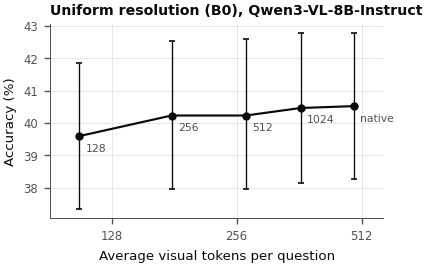

⏱ P2.F1 figure: uniform frontier | wall 1.20 s | CPU 1.07 s (0.89 cores, sys 5.8%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
figure -> /content/rave_work/figures/fig_p2_2_gate_quality.pdf


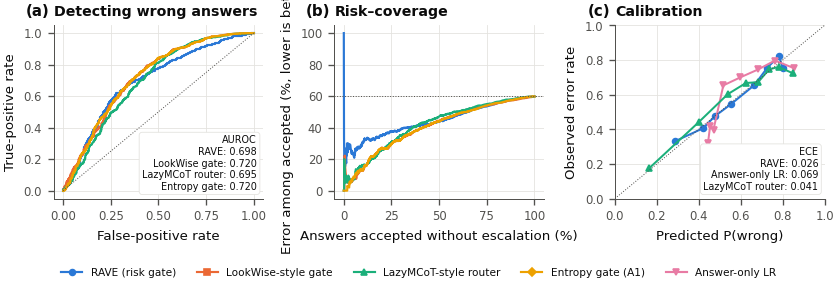

⏱ P2.F2 figure: gate quality | wall 1.27 s | CPU 1.28 s (1.01 cores, sys 8.9%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
figure -> /content/rave_work/figures/fig_p2_3_accuracy_by_image_type.pdf


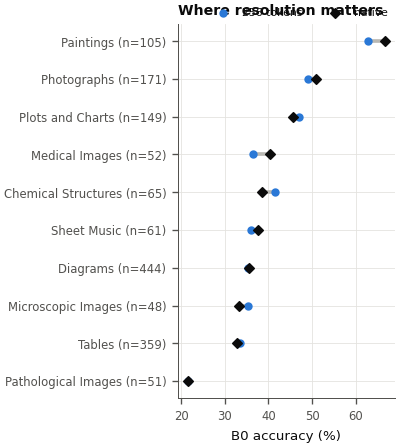

⏱ P2.F3 figure: accuracy by image type | wall 0.67 s | CPU 0.67 s (1.01 cores, sys 8.7%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
figure -> /content/rave_work/figures/fig_p2_4_risk_control.pdf


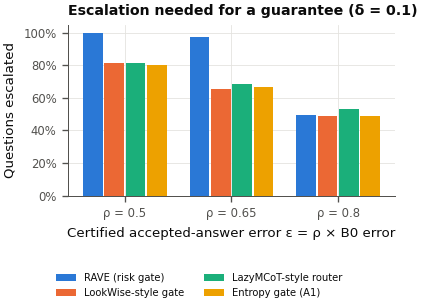

⏱ P2.F4 figure: risk control | wall 0.80 s | CPU 0.81 s (1.01 cores, sys 8.3%) | GPU 0.00 s (no GPU used) | RAM peak 6 GB | A100 time 0.12/7 h
⏱ cell 15: import textwrap | wall 3.98 s | CPU 3.87 s (0.97 cores, sys 8.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.21 kJ, peak 17.54 GB | RAM peak 6 GB | A100 time 0.12/7 h


In [17]:
import textwrap
from matplotlib.ticker import PercentFormatter

with Phase("P2.F1 figure: uniform frontier", budget_min=1):
    fig, ax = plt.subplots(figsize=(COL1, 2.4))
    F_ = FRONTIER
    ax.errorbar(F_.avg_visual_tokens, 100 * F_.acc, yerr=[100 * (F_.acc - F_.ci_lo), 100 * (F_.ci_hi - F_.acc)],
                color=COLORS["B0"], marker="o", ms=4, lw=1.3, capsize=2, elinewidth=0.8)
    for r in F_.itertuples():
        ax.annotate(r.base if r.base == "native" else f"{r.base}", (r.avg_visual_tokens, 100 * r.acc),
                    xytext=(4, -9), textcoords="offset points", fontsize=6.5, color=INK2)
    token_axis(ax, F_.avg_visual_tokens.min(), F_.avg_visual_tokens.max())
    ax.set_xlabel("Average visual tokens per question")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"Uniform resolution (B0), {MODEL_ID.split('/')[-1]}")
    fig.tight_layout()
    save_fig(fig, "fig_p2_1_uniform_frontier")

with Phase("P2.F2 figure: gate quality", budget_min=1):
    G = GATES[MAIN_BASE]; y = G["y"]
    fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.45))
    box = dict(boxstyle="round,pad=0.3", fc="white", ec=GRID_C, lw=0.5)
    ax = axs[0]
    if len(np.unique(y)) == 2:
        for name in GATE_NAMES:
            fpr, tpr, _ = roc_curve(y, G["S"][name])
            ax.plot(fpr, tpr, color=COLORS[name], lw=1.3)
        ax.text(0.97, 0.04, "AUROC\n" + "\n".join(f"{NAMES[n].split(' (')[0].replace('-style', '')}: {safe_auc(y, G['S'][n]):.3f}"
                                                   for n in GATE_NAMES), transform=ax.transAxes, ha="right", va="bottom",
                fontsize=5.8, color=INK, bbox=box)
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
    ax.set_title("Detecting wrong answers")
    panel(ax, "a")
    ax = axs[1]
    for name in GATE_NAMES:
        o = np.argsort(G["S"][name], kind="stable"); e = y[o]
        cov = np.arange(1, len(e) + 1) / len(e)
        ax.plot(100 * cov, 100 * np.cumsum(e) / np.arange(1, len(e) + 1), color=COLORS[name], lw=1.3)
    ax.axhline(100 * y.mean(), color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("Answers accepted without escalation (%)"); ax.set_ylabel("Error among accepted (%, lower is better)")
    ax.set_title("Risk–coverage")
    panel(ax, "b")
    ax = axs[2]
    ece_txt = []
    for name, key in (("RAVE_risk", "RAVE_risk_iso"), ("LR_logit", "LR_logit"), ("LazyMCoT_GBDT", "LazyMCoT_GBDT")):
        p = G["S"][key]; edges = np.quantile(p, np.linspace(0, 1, 9)); edges[-1] += 1e-9
        idx = np.clip(np.digitize(p, edges) - 1, 0, 7)
        xs = [p[idx == b].mean() for b in range(8) if (idx == b).sum() >= 3]
        ys = [y[idx == b].mean() for b in range(8) if (idx == b).sum() >= 3]
        ax.plot(xs, ys, color=COLORS[name], marker=MARKERS[name], ms=3.5, lw=1.2)
        ece_txt.append(f"{NAMES[name].split(' (')[0].replace('-style', '')}: {ece(y, p):.3f}")
    ax.text(0.97, 0.04, "ECE\n" + "\n".join(ece_txt), transform=ax.transAxes, ha="right", va="bottom", fontsize=5.8,
            color=INK, bbox=box)
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Predicted P(wrong)"); ax.set_ylabel("Observed error rate")
    ax.set_title("Calibration")
    panel(ax, "c")
    handles = [Line2D([], [], color=COLORS[n], marker=MARKERS[n], ms=3.5, lw=1.3, label=NAMES[n])
               for n in GATE_NAMES + ["LR_logit"]]
    fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02), fontsize=6.3)
    fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=1.0)
    save_fig(fig, "fig_p2_2_gate_quality")

with Phase("P2.F3 figure: accuracy by image type", budget_min=1):
    dm = B0[MAIN_BASE].merge(Q[["qid", "img_type"]], on="qid")
    dn = B0["native"].merge(Q[["qid", "img_type"]], on="qid")
    rows = []
    for t in TOP_TYPES:
        sel = dm.img_type.map(lambda s_: t in json.loads(s_))
        seln = dn.img_type.map(lambda s_: t in json.loads(s_))
        if sel.sum() >= 3:
            rows.append(dict(t=t, n=int(sel.sum()), a256=100 * dm.correct[sel].mean(), anat=100 * dn.correct[seln].mean()))
    R = pd.DataFrame(rows).sort_values("anat") if rows else pd.DataFrame(columns=["t", "n", "a256", "anat"])
    fig, ax = plt.subplots(figsize=(COL1, 0.32 * max(len(R), 3) + 0.7))
    ys = np.arange(len(R))
    for yv, r in zip(ys, R.itertuples()):
        ax.plot([r.a256, r.anat], [yv, yv], color="#b9b8b3", lw=2.2, solid_capstyle="round", zorder=1)
    ax.scatter(R.a256, ys, color=COLORS["RAVE_risk"], s=16, zorder=2, label=f"{MAIN_BASE} tokens")
    ax.scatter(R.anat, ys, color=INK, s=16, marker="D", zorder=2, label="native")
    ax.set_yticks(ys, [f"{textwrap.shorten(t, 26, placeholder='…')} (n={n})" for t, n in zip(R.t, R.n)] if len(R) else [])
    ax.set_xlabel("B0 accuracy (%)")
    ax.set_title("Where resolution matters")
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=6.5, borderaxespad=0.2)
    fig.tight_layout()
    save_fig(fig, "fig_p2_3_accuracy_by_image_type")

with Phase("P2.F4 figure: risk control", budget_min=1):
    L = LTT_TAB[LTT_TAB.base == MAIN_BASE]
    fig, ax = plt.subplots(figsize=(COL1, 2.6))
    w_ = 0.8 / len(GATE_NAMES)
    for i, name in enumerate(GATE_NAMES):
        sub = L[L.gate == name].sort_values("rho")
        xs = np.arange(len(sub)) + (i - (len(GATE_NAMES) - 1) / 2) * w_
        ax.bar(xs, 100 * sub.escalation_rate, width=w_ * 0.92, color=COLORS[name], label=NAMES[name])
    ax.set_xticks(np.arange(len(LTT_RHO)), [f"ρ = {r:g}" for r in LTT_RHO])
    ax.set_xlabel("Certified accepted-answer error ε = ρ × B0 error")
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_ylim(0, 105)
    ax.set_ylabel("Questions escalated")
    ax.set_title(f"Escalation needed for a guarantee (δ = {LTT_DELTA})")
    fig.legend(*ax.get_legend_handles_labels(), fontsize=6, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    save_fig(fig, "fig_p2_4_risk_control")

## Summary — CPU and GPU time of Portion 2, and what Portion 3 will cost

In [18]:
window("end of Portion 2")
P3_PASSES = [f"{k}@{b}" for b in RISK_BASES for k in ["joint_top1", "b2_upscaled", "croponly_top1", "joint_rand",
                                                      "b1_grid4", "joint_top3"]]
print(f"Portion 3 dense passes ({len(P3_PASSES)}): projected {PROJ_MIN[P3_PASSES].sum():.0f} min of wall time")
time_report("P2")
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P2_GPU_B0_gates_prereg")

⏱ A100 time end of Portion 2: 0.12 h used, 6.88 h left of 7 h (P2–P4 cells)
Portion 3 dense passes (12): projected 45 min of wall time
[P2] 25 cells | wall 10.6 min | CPU 15.5 CPU-min (1.5 cores avg) | GPU busy 10.18 min (phases) / 5.00 min (cells, NVML) | GPU energy 129.9 kJ | A100 time used (P2–P4) 0.12 h of 7
Drive sync: 0 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
notebook with outputs -> /content/drive/MyDrive/Koushik 2/notebooks/RAVE_v4_P2_GPU_B0_gates_prereg_executed_20261018_1326.ipynb
⏱ cell 16: window("end of Portion 2") | wall 1.62 s | CPU 0.05 s (0.03 cores, sys 1.2%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.08 kJ, peak 17.54 GB | RAM peak 6 GB | A100 time 0.12/7 h
